In [1]:
# # -----------------------
# # Nbits comparison plots (avg_tokens=0 and 1, n_tokens=20)
# # -----------------------
# n_tokens = 20
# avg_tokens_list = [0, 1]

# for language_pair_id, (languageA, languageB) in enumerate(language_pairs):
#     layers = get_layers(model, depths)
#     x = layers / depths[model]

#     for avg_tokens in avg_tokens_list:
#         mean_ii_0, _ = load_ii_curves(
#             base="./results/santiago/",
#             batch_shuffle=batch_shuffle,
#             model=model,
#             aux_A=aux_A,
#             aux_B=aux_B,
#             n_files=n_files,
#             min_token_length=min_token_length,
#             languageA=languageA,
#             languageB=languageB,
#             mask=mask,
#             k=k_II,
#             Nbits=0,
#             seeds=[0],
#             n_tokens=n_tokens,
#             avg_tokens=avg_tokens,
#         )

#         mean_ii_1, _ = load_ii_curves(
#             base="./results/santiago/",
#             batch_shuffle=batch_shuffle,
#             model=model,
#             aux_A=aux_A,
#             aux_B=aux_B,
#             n_files=n_files,
#             min_token_length=min_token_length,
#             languageA=languageA,
#             languageB=languageB,
#             mask=mask,
#             k=k_II,
#             Nbits=1,
#             seeds=seeds_II,
#             n_tokens=n_tokens,
#             avg_tokens=avg_tokens,
#         )

#         fig, ax = plt.subplots(1, 1, figsize=(6, 4))
#         # AB direction: plot Nbits=0 and Nbits=1 superimposed
#         ax.plot(x, mean_ii_0[0], label="Nbits=0", linestyle='-', color=colors[0], marker='o')
#         ax.plot(x, mean_ii_1[0], label="Nbits=1", linestyle='--', color=colors[0], marker='s')

#         ax.set_xlabel("relative depth")
#         ax.set_ylabel("Information Imbalance")
#         ax.set_title(f"{languageA.capitalize()} → {languageB.capitalize()} | T={n_tokens} | avg={avg_tokens}")
#         ax.legend()
#         plt.show()


In [2]:
import sys
import os
import matplotlib.pyplot as plt
import numpy as np
sys.path.append('../../')
from utils_plots import (apply_plot_style, 
                         get_layers, 
                         load_ii_curves, 
                         linestyle_for_language, 
                         _min_token_length)
eps = 1E-7
colors, markers, _linestyles = apply_plot_style()
plot_id = 0
sys.path.append(os.path.expanduser('~/syn-sem'))
from modelpaths import get_model_depths
depths = get_model_depths()


/home/acevedo/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


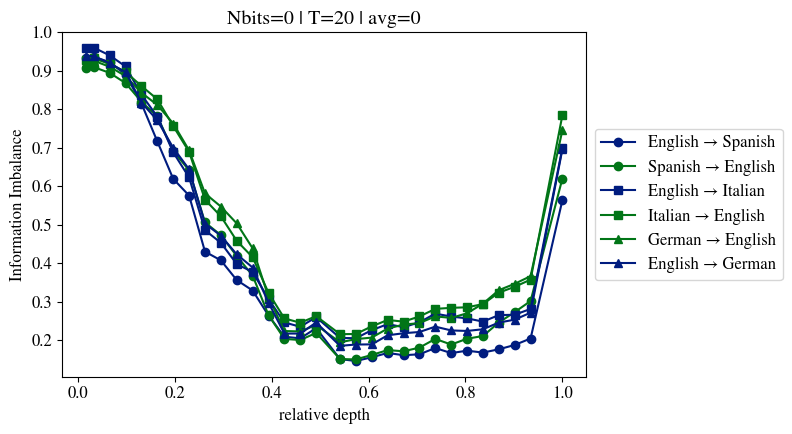

In [3]:
model = 'deepseek'
_model ='deepseek'

# model = "llama"
# _model = 'llama8b'

# MODEL_PRETTY = {"deepseek": "DeepSeek-V3", "llama": "Llama3-8b"}
# _model = MODEL_PRETTY.get(model, model)

mask = 2
n_files = 500
batch_size = 10
Ns = batch_size * n_files
batch_shuffle = 0


aux_A = "source"
aux_B = "target"
k_II = 10
avg_tokens = 0
n_tokens = 20
Nbits = 0
seeds = list(range(5))
language_pairs = [
    ("english", "spanish"),
    ("english", "italian"),
    ("german", "english"),
    # ("english", "french"),
    # ("english", "dutch"),
    # ("english", "hungarian"),
]

layers = get_layers(_model, depths)
x = layers / depths[_model]

fig, ax = plt.subplots(1, 1, figsize=(7, 4.5))

markers = ["o", "s", "^", "D", "v", "P", "X", "*", "+", "x"]

for i, (languageA, languageB) in enumerate(language_pairs):
    mean_ii, _ = load_ii_curves(
        base="../results/santiago/",
        batch_shuffle=batch_shuffle,
        model=model,
        aux_A=aux_A,
        aux_B=aux_B,
        n_files=n_files,
        min_token_length=_min_token_length(model, languageA, languageB),
        languageA=languageA,
        languageB=languageB,
        mask=mask,
        k=k_II,
        Nbits=Nbits,
        seeds=seeds,
        n_tokens=n_tokens,
        avg_tokens=avg_tokens,
    )

    if languageA == "german" and languageB == "english":
        color_AB = colors[1]
        color_BA = colors[0]
    else:
        color_AB = colors[0]
        color_BA = colors[1]
    marker = markers[i % len(markers)]

    # AB
    ax.plot(
        x,
        mean_ii[0],
        label=f"{languageA.capitalize()} → {languageB.capitalize()}",
        linestyle='-',
        marker=marker,
        color=color_AB,
    )

    # BA
    ax.plot(
        x,
        mean_ii[1],
        label=f"{languageB.capitalize()} → {languageA.capitalize()}",
        linestyle='-',
        marker=marker,
        color=color_BA,
    )

ax.set_xlabel("relative depth")
ax.set_ylabel("Information Imbalance")
ax.set_title(f"Nbits={Nbits} | T={n_tokens} | avg={avg_tokens}")

# Legend outside
box = ax.get_position()
ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))

plt.show()

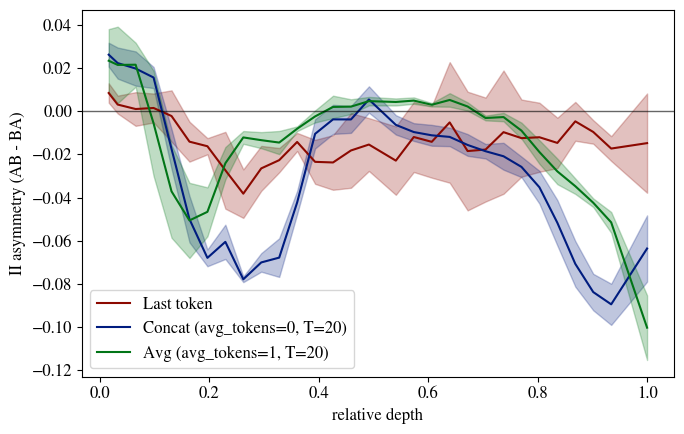

In [4]:
avg_tokens_cases = [
    (0, "Concat"),
    (1, "Avg"),
]

n_tokens_cases = [
    (1, "Last token"),
    (n_tokens, f"T={n_tokens}"),
]

linestyles = ["-", "--"]

fig, ax = plt.subplots(1, 1, figsize=(7, 4.5))

for token_case_id, (n_tokens_case, token_label) in enumerate(n_tokens_cases):
    for case_id, (avg_tokens_case, case_label) in enumerate(avg_tokens_cases):
        if n_tokens_case == 1 and avg_tokens_case == 1:
            continue

        asym_list = []
        for (languageA, languageB) in language_pairs:
            mean_ii, _ = load_ii_curves(
                base="../results/santiago/",
                batch_shuffle=batch_shuffle,
                model=model,
                aux_A=aux_A,
                aux_B=aux_B,
                n_files=n_files,
                min_token_length=_min_token_length(model, languageA, languageB),
                languageA=languageA,
                languageB=languageB,
                mask=mask,
                k=k_II,
                Nbits=Nbits,
                seeds=seeds,
                n_tokens=n_tokens_case,
                avg_tokens=avg_tokens_case,
            )
            a = mean_ii[0] - mean_ii[1]
            a = -1 * a if languageA == "german" else a
            asym_list.append(a)

        asym = np.stack(asym_list, axis=0)
        asym_mean = asym.mean(axis=0)
        asym_std = asym.std(axis=0)

        if n_tokens_case == 1:
            color = colors[2 % len(colors)]
        else:
            color = colors[case_id % len(colors)]

        if n_tokens_case == 1:
            label = "Last token"
        else:
            label = f"{case_label} (avg_tokens={avg_tokens_case}, {token_label})"

        ax.plot(
            x,
            asym_mean,
            color=color,
            label=label,
        )
        ax.fill_between(x, asym_mean - asym_std, asym_mean + asym_std, color=color, alpha=0.25)

ax.axhline(0, color='black', linewidth=1, alpha=0.6)
ax.set_xlabel("relative depth")
ax.set_ylabel("II asymmetry (AB - BA)")
ax.legend()
# fig.savefig(fname=f'../results/figs/fig1_asym_avg_languages.pdf', bbox_inches='tight')
plt.show()
